# M01-3 | The Three Switches of QuantizationConfig

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/bobondemon/pt2e_quantize_and_deploy/blob/main/en/m01_hello_pt2e/03_config_matrix.ipynb)

The quantizers in M01-1 and M01-2 were all created with `get_xnnpack_quantizer(is_per_channel=True)`,
which underneath uses `get_symmetric_quantization_config(...)` to produce a `QuantizationConfig`, then `set_global` applies it to the whole model.
This config has three switches:

| Parameter | Meaning |
|---|---|
| `is_per_channel` | One scale per output channel of the weight (False: the whole weight shares one) |
| `is_qat` | Observers become fake quant, which really does quantize → dequantize in forward, for QAT training |
| `is_dynamic` | Activation qparams are not fixed during calibration but computed at run time from the current input |

This notebook runs various combinations on the same model with the same calibration data, and looks at how the graphs and numbers differ.


In [1]:
#| include: false
# When running on Google Colab: download the course code and install the packages (takes a few minutes the first time).
# When running on your own machine (see the README for the environment), this cell does nothing.
import sys

if "google.colab" in sys.modules:
    import os
    import subprocess

    repo = "/content/pt2e_quantize_and_deploy"
    if not os.path.exists(repo):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/bobondemon/pt2e_quantize_and_deploy.git", repo], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                        "--extra-index-url", "https://download.pytorch.org/whl/cpu",
                        "torch==2.14.0+cpu", "torchao==0.18.0", "onnx==1.23.0", "onnxscript==0.7.2",
                        "onnxruntime==1.30.0", "tabulate", "graphviz"], check=True)
    sys.path.insert(0, repo)  # so the notebook can import this course's common/
    os.chdir(f"{repo}/en/m01_hello_pt2e")

In [2]:
import copy

import torch

from common.data import calibration_batches
from common.graph_utils import observer_nodes, qdq_nodes, short, sqnr
from common.models import example_inputs, get_model
from common.pt2e import convert_pt2e, export_module, get_xnnpack_quantizer, prepare_pt2e, quiet
from common.viz import draw, table

quiet()
_ = torch.manual_seed(0)

## A. Four Settings Side by Side

`run_one()` runs one setting from export to convert and returns: how many observers were inserted, their types, the q/dq count, and the output SQNR against fp32.
The model is an untrained `TinyConvNet`; here we only compare outputs before and after quantization, not accuracy.


In [3]:
def run_one(model, ex, **cfg):
    quantizer, _ = get_xnnpack_quantizer(**cfg)
    prepared = prepare_pt2e(export_module(copy.deepcopy(model), ex), quantizer)
    obs_types = sorted({type(m).__name__ for _, m in observer_nodes(prepared)})
    n_obs = len(observer_nodes(prepared))
    with torch.no_grad():
        for batch in calibration_batches(n=256, batch_size=32):
            prepared(*batch)
    converted = convert_pt2e(prepared)
    with torch.no_grad():
        out_sqnr = sqnr(model(*ex), converted(*ex))
    return [n_obs, ", ".join(obs_types), len(qdq_nodes(converted)), f"{out_sqnr:.1f}"]


model = get_model("tiny").eval()
ex = example_inputs(8)
configs = {
    "per-tensor weight": dict(is_per_channel=False),
    "per-channel weight": dict(is_per_channel=True),
    "per-channel + is_qat": dict(is_per_channel=True, is_qat=True),
    "per-channel + is_dynamic": dict(is_per_channel=True, is_dynamic=True),
}
results = {name: run_one(model, ex, **cfg) for name, cfg in configs.items()}
table([[name, *r] for name, r in results.items()],
      ["Setting", "#observer", "observer types", "#q/dq", "Output SQNR (dB)"])

Setting,#observer,observer types,#q/dq,Output SQNR (dB)
per-tensor weight,16,"HistogramObserver, MinMaxObserver",28,20.6
per-channel weight,16,"HistogramObserver, PerChannelMinMaxObserver",28,20.6
per-channel + is_qat,16,FusedMovingAvgObsFakeQuantize,28,17.4
per-channel + is_dynamic,2,"PerChannelMinMaxObserver, PlaceholderObserver",3,50.3


Three things worth asking about:

1. The SQNR of per-tensor and per-channel is almost the same. Is per-channel useless? (Section B)
2. `is_dynamic` has only 2 observers left, yet its SQNR is much higher. (Section C)
3. `is_qat` replaces the observers with `FusedMovingAvgObsFakeQuantize`. It is for training; M06 is where it is actually used to train.
   For now, just remember "the same quantizer with a different config inserts different things into the graph".

## B. per-tensor ≈ per-channel: The Error Mainly Comes from Activations

Quantize only the weights, keep activations in fp32, and see how much the output differs.
The method is to directly replace the weight of every conv / linear in the model with its quantize → dequantize value
(BN has not been folded into conv yet, so this only approximates what PT2E does).


In [4]:
def fake_quant_weight(w, per_channel):
    """Symmetric int8: scale = absmax / 127; with per-channel, one per output channel."""
    dims = tuple(range(1, w.dim()))
    scale = (w.abs().amax(dim=dims, keepdim=True) if per_channel else w.abs().max()) / 127
    return (w / scale).round().clamp(-127, 127) * scale


def weight_only_sqnr(model, ex, per_channel):
    m = copy.deepcopy(model)
    with torch.no_grad():
        for mod in m.modules():
            if isinstance(mod, (torch.nn.Conv2d, torch.nn.Linear)):
                mod.weight.copy_(fake_quant_weight(mod.weight, per_channel))
        return sqnr(model(*ex), m(*ex))


rows = [[name, f"{weight_only_sqnr(model, ex, pc):.1f}", results[full][3]]
        for name, pc, full in [("per-tensor", False, "per-tensor weight"),
                               ("per-channel", True, "per-channel weight")]]
table(rows, ["weight granularity", "SQNR with weight-only quantization (dB)", "SQNR with full quantization (dB)"])

weight granularity,SQNR with weight-only quantization (dB),SQNR with full quantization (dB)
per-tensor,48.7,20.6
per-channel,46.1,20.6


In [5]:
for _, w_only, full in rows:
    assert float(w_only) > float(full) + 20

When only the weights are quantized, the SQNR of both granularities is more than 20 dB higher than with full quantization: the error of this model mainly comes from activations,
so which granularity the weight uses makes no visible difference in the final SQNR.
Another reason is that this model was just initialized, so the weight ranges of the channels are about the same.

The value of per-channel only shows when "the ranges differ a lot between channels". Construct a weight whose channel 0 is 100 times larger:


In [6]:
w = torch.randn(4, 3, 3, 3)
w[0] *= 100.0
w_pt, w_pc = fake_quant_weight(w, per_channel=False), fake_quant_weight(w, per_channel=True)

rows = [[c, f"{float(w[c].abs().max()):.2f}", f"{sqnr(w[c], w_pt[c]):.1f}", f"{sqnr(w[c], w_pc[c]):.1f}"]
        for c in range(w.shape[0])]
rows.append(["whole tensor", "", f"{sqnr(w, w_pt):.1f}", f"{sqnr(w, w_pc):.1f}"])
table(rows, ["channel", "absmax", "per-tensor SQNR (dB)", "per-channel SQNR (dB)"])

channel,absmax,per-tensor SQNR (dB),per-channel SQNR (dB)
0,302.52,44.0,44.0
1,3.20,4.2,44.4
2,2.55,4.9,45.7
3,2.23,2.4,45.6
whole tensor,,38.5,44.0


per-tensor has only one scale, determined by the largest channel, channel 0 (absmax / 127).
The values of the other channels are only a few times one scale step or less, so after quantization they are almost all squashed to 0, and the SQNR drops to single digits.
The SQNR of the "whole tensor" row is dominated by channel 0 and hides this problem; you have to look channel by channel.

Per-channel for weights has almost no cost: the scales are constants and are stored along with the weight. Per-channel for activations, on the other hand, is not supported by most hardware.

## C. `is_dynamic`: Only linear Is Quantized

The high SQNR of dynamic is because less is quantized. First look at the annotate result:


In [7]:
gm = export_module(copy.deepcopy(model), ex)
q_dyn, _ = get_xnnpack_quantizer(is_per_channel=True, is_dynamic=True)
annotated = q_dyn.annotate(copy.deepcopy(gm))
marked = [n.name for n in annotated.graph.nodes if "quantization_annotation" in n.meta]
print("Annotated nodes:", marked)
assert "linear" in marked and not any(name.startswith("conv2d") for name in marked)

Annotated nodes: ['fc_weight', 'fc_bias', 'linear']


Only `linear` (and its weight and bias) has annotations; not a single conv does. The reason is in the quantizer's source
(torchao 0.18's [`torchao/testing/pt2e/_xnnpack_quantizer.py`](https://github.com/pytorch/ao/blob/main/torchao/testing/pt2e/_xnnpack_quantizer.py)):

- As soon as `annotate()` sees that the global config is dynamic, it takes the dynamic annotation path entirely; the static annotators for conv, add, and so on are never run.
- The dynamic path only handles the list `DYNAMIC_OPS = ["linear"]`.

So the dynamic here is **not** "linear uses static and conv becomes dynamic", but "only linear is quantized, and in the dynamic way".
After convert, look at what operations remain on the graph:


In [8]:
prepared_dyn = prepare_pt2e(gm, q_dyn)
with torch.no_grad():
    prepared_dyn(*ex)
converted_dyn = convert_pt2e(prepared_dyn)
print(" → ".join(short(n.target) for n in converted_dyn.graph.nodes if n.op == "call_function"))

dequantize_per_channel → conv2d → relu → max_pool2d → conv2d → relu → conv2d → add → relu → max_pool2d → conv2d → relu → adaptive_avg_pool2d → flatten → choose_qparams → getitem → getitem → quantize_per_tensor → dequantize_per_tensor → linear


In [9]:
convs = [n for n in converted_dyn.graph.nodes if short(n.target) == "conv2d"]
assert all(a.op != "call_function" or "quantize" not in str(a.target) for c in convs for a in c.all_input_nodes)
assert any(short(n.target) == "choose_qparams" for n in converted_dyn.graph.nodes)
print(f"None of the {len(convs)} conv2d inputs has a dequantize: conv runs in fp32")

None of the 4 conv2d inputs has a dequantize: conv runs in fp32


There is no dq in front of conv2d; it computes directly with the fp32 weight. Quantization only happens around linear:


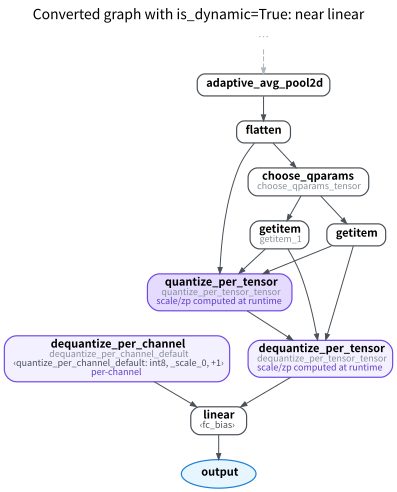

In [10]:
draw(converted_dyn, focus=["linear"], hops=4, title="Converted graph with is_dynamic=True: near linear")

On the same linear, the weight and the input use two different approaches:

| Target | How it is quantized |
|---|---|
| linear's weight | Static: stored as an int8 constant at convert time (per-channel), leaving only `dequantize_per_channel` |
| linear's input activation | Dynamic: prepare inserts a `PlaceholderObserver` (collects no statistics, just holds the place); after convert it becomes `choose_qparams` → `quantize_per_tensor` → `dequantize_per_tensor`, and each run `choose_qparams` computes scale / zp from the current input |
| conv and other ops | Not quantized, no q/dq |

In other words, dynamic means "the activation's qparams are computed at run time and need no calibration", not that every op is switched to a different quantization scheme;
which ops support dynamic quantization is decided by the quantizer. With a different quantizer the answer may differ:
the `XNNPACKQuantizer` shipped with executorch (used in M08) supports dynamic quantization for the patterns `linear`, `conv`, and `conv_transpose`
(from reading the executorch 1.5 source; `conv_relu` is not among them).

Back to the table in Section A: the dynamic row quantized only linear while the other three rows quantized the whole model, so their SQNR cannot be compared directly.

## Summary

- The config decides "which observers are inserted and which ops are quantized"; the same quantizer with a different config gives a different graph.
- Before comparing SQNR, first confirm which ops were quantized; otherwise you are comparing different things.
- Per-channel weights matter only when channel ranges differ a lot; look at the error channel by channel, because the overall number is dominated by the largest channel.
